# 📈 Regresi Linear


Regresi linear adalah model **paling dasar** dalam machine learning: mencari garis (atau bidang)
yang paling mendekati hubungan antara fitur dan target.

**Studi kasus:** memprediksi **harga rumah**.

| Fitur | Arti |
|---|---|
| `bedrooms` | jumlah kamar tidur |
| `bathrooms` | jumlah kamar mandi |
| `sqft_living` | luas bangunan (kaki persegi) |
| `sqft_lot` | luas tanah (kaki persegi) |
| `statezip` | **lokasi** (kode pos) |

**Target:** `price` (dolar AS)

> 💡 `statezip` berisi teks, bukan angka. Nanti kita ubah dulu jadi angka dengan
> **one-hot encoding** — lihat bagian 4️⃣.

Alur notebook:

1. Memuat & membersihkan data
2. Menyiapkan fitur (termasuk lokasi) & membagi data
3. Melatih model regresi linear
4. Evaluasi dengan RMSE & visualisasi
5. Memprediksi rumah baru

> 💡 **Jalankan setiap sel** dengan memilihnya dan tekan `Shift + Enter`.

---
## 0️⃣ Setup & Import

Kali ini kita pakai **scikit-learn**, pustaka machine learning paling populer di Python.
Model regresi linear sudah tersedia siap pakai — kita tidak perlu menulis algoritmanya sendiri.

> 📦 Jika scikit-learn belum terinstall: `uv add scikit-learn` atau `pip install scikit-learn`

In [35]:
# ── Import pustaka ──
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import root_mean_squared_error

%matplotlib inline

import sklearn
print(f"scikit-learn version : {sklearn.__version__}")
print(f"NumPy version        : {np.__version__}")
print(f"Pandas version       : {pd.__version__}")

scikit-learn version : 1.9.1
NumPy version        : 2.5.3
Pandas version       : 3.0.6


---
## 1️⃣ Memuat Dataset

Dataset `house_price.csv` berisi 4.600 penjualan rumah di wilayah King County, Washington (AS).

In [36]:
# ── Membaca CSV ──
df = pd.read_csv("data/house_price.csv")

print(f"Shape (baris, kolom) : {df.shape}")
print(f"Nama kolom           : {list(df.columns)}")

Shape (baris, kolom) : (4600, 18)
Nama kolom           : ['date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'street', 'city', 'statezip', 'country']


In [37]:
# ── 5 baris pertama ──
df.head()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


In [38]:
# ── Statistik deskriptif kolom yang kita pakai ──
FITUR  = ["bedrooms", "bathrooms", "sqft_living", "sqft_lot"]
TARGET = "price"

df[FITUR + ["statezip", TARGET]].describe().round(2)

,bedrooms,bathrooms,sqft_living,sqft_lot,price
count,4600.00,4600.00,4600.00,4600.00,4600.00
mean,3.40,2.16,2139.35,14852.52,551962.99
std,0.91,0.78,963.21,35884.44,563834.70
min,0.00,0.00,370.00,638.00,0.00
25%,3.00,1.75,1460.00,5000.75,322875.00
50%,3.00,2.25,1980.00,7683.00,460943.46
75%,4.00,2.50,2620.00,11001.25,654962.50
max,9.00,8.00,13540.00,1074218.00,26590000.00


In [39]:
# ── Cek data kosong ──
kosong = df[FITUR + ["statezip", TARGET]].isna().sum()
print("Jumlah nilai kosong per kolom:")
print(kosong)
print(f"\nTotal data kosong: {kosong.sum()}")

Jumlah nilai kosong per kolom:
bedrooms       0
bathrooms      0
sqft_living    0
sqft_lot       0
statezip       0
price          0
dtype: int64

Total data kosong: 0


---
## 2️⃣ Pembersihan Data

Sebelum melatih model, periksa dulu **kualitas data**. Dua masalah yang umum: nilai tidak masuk
akal dan *outlier* (pencilan) ekstrem.

In [40]:
# ── Masalah 1: nilai tidak masuk akal ──
print(f"Rumah dengan price == 0     : {(df[TARGET] == 0).sum()}")
print(f"Rumah dengan price < 10.000 : {(df[TARGET] < 10_000).sum()}")
print(f"Rumah dengan bedrooms == 0  : {(df['bedrooms'] == 0).sum()}")

Rumah dengan price == 0     : 49
Rumah dengan price < 10.000 : 50
Rumah dengan bedrooms == 0  : 2


In [41]:
# ── Masalah 2: outlier ekstrem ──
# Lihat 5 rumah termahal — apakah harganya masuk akal?
df.nlargest(5, TARGET)[["price", "bedrooms", "bathrooms", "sqft_living", "sqft_lot", "statezip"]]

,price,bedrooms,bathrooms,sqft_living,sqft_lot,statezip
4350,26590000.0,3.0,2.00,1180,7793,WA 98031
4346,12899000.0,3.0,2.50,2190,11394,WA 98199
2286,7062500.0,5.0,4.50,10040,37325,WA 98004
2654,4668000.0,5.0,6.75,9640,13068,WA 98040
2761,4489000.0,4.0,3.00,6430,27517,WA 98004


Rumah 1.180 sqft di Kent seharga **$26,6 juta** jelas bukan data wajar — kemungkinan salah input.
Outlier seperti ini berbahaya karena **menarik garis regresi** dan membuat error membengkak.

**Strategi:** buang harga nol, lalu potong nilai ekstrem di atas persentil ke-99 (1% teratas)
untuk `price` dan `sqft_lot`.

In [42]:
# ── Bersihkan data ──
n_awal = len(df)

# 1. Buang harga nol / tidak masuk akal
df = df[df[TARGET] > 0]

# 2. Buang 1% nilai ekstrem pada price dan sqft_lot
batas_price = df[TARGET].quantile(0.99)
batas_lot   = df["sqft_lot"].quantile(0.99)
df = df[(df[TARGET] <= batas_price) & (df["sqft_lot"] <= batas_lot)]

df = df.reset_index(drop=True)

print(f"Baris sebelum dibersihkan : {n_awal}")
print(f"Baris setelah dibersihkan : {len(df)}")
print(f"Baris dibuang             : {n_awal - len(df)} ({(n_awal - len(df)) / n_awal:.1%})")
print(f"\nBatas price   (p99) : ${batas_price:,.0f}")
print(f"Batas sqft_lot (p99): {batas_lot:,.0f} sqft")
print(f"\nRentang harga sekarang: ${df[TARGET].min():,.0f} — ${df[TARGET].max():,.0f}")

Baris sebelum dibersihkan : 4600
Baris setelah dibersihkan : 4460
Baris dibuang             : 140 (3.0%)

Batas price   (p99) : $2,016,000
Batas sqft_lot (p99): 204,950 sqft

Rentang harga sekarang: $7,800 — $2,005,000


---
## 3️⃣ Teori Singkat: Regresi Linear

Model regresi linear memprediksi target sebagai **kombinasi linear** dari fitur:

$$\hat{y} = w_1 x_1 + w_2 x_2 + \dots + w_p x_p + b$$

dengan:
- $x_1 \dots x_p$ = fitur-fitur rumah
- $w_1 \dots w_p$ = **koefisien** — seberapa besar pengaruh tiap fitur
- $b$ = **intersep** — nilai dasar saat semua fitur nol

**Bagaimana scikit-learn mencari nilai terbaik?** Model meminimalkan **Mean Squared Error (MSE)**:

$$J = \frac{1}{n}\sum_{i=1}^{n}(\hat{y}_i - y_i)^2$$

Untuk regresi linear, nilai minimum ini bisa dihitung **langsung** (*least squares*) — tidak perlu
iterasi. Kita cukup memanggil `.fit()`, dan scikit-learn mengurus sisanya.

### Masalah: lokasi itu teks, bukan angka

Harga rumah sangat ditentukan **lokasi**, tapi `statezip` isinya `"WA 98115"` — teks. Teks tidak
bisa dikalikan dengan koefisien. Solusinya **one-hot encoding**: buat satu kolom baru untuk setiap
kode pos, isinya `1` kalau rumah itu di kode pos tersebut dan `0` kalau bukan.

| statezip asli | zip_WA 98042 | zip_WA 98052 | zip_WA 98115 |
|---|---|---|---|
| WA 98115 | 0 | 0 | 1 |
| WA 98052 | 0 | 1 | 0 |
| WA 98115 | 0 | 0 | 1 |

Dengan begitu setiap lokasi punya koefisiennya sendiri, dan model bisa belajar bahwa kode pos A
jauh lebih mahal daripada kode pos B.

---
## 4️⃣ Menyiapkan Fitur & Membagi Data

### Kenapa data harus dipisah?

Kalau model diuji pada data yang **sama** dengan data latihannya, kita tidak tahu apakah model
benar-benar belajar atau hanya menghafal. Jadi data dibagi:

- **Train set (80%)** — untuk melatih model
- **Test set (20%)** — untuk menguji pada data yang belum pernah dilihat

In [43]:
# ── Bentuk X (fitur) dan y (target) ──
# Lokasi masih berupa teks, jadi diubah dulu dengan one-hot encoding.
X = pd.concat([
    df[FITUR],
    pd.get_dummies(df["statezip"], prefix="zip", drop_first=True),
], axis=1)

y = df[TARGET]

print(f"X shape : {X.shape}  → {X.shape[0]} rumah, {X.shape[1]} kolom")
print(f"  · {len(FITUR)} kolom fitur fisik : {FITUR}")
print(f"  · {X.shape[1] - len(FITUR)} kolom lokasi   : hasil one-hot dari statezip")
print(f"y shape : {y.shape}")

X shape : (4460, 80)  → 4460 rumah, 80 kolom
  · 4 kolom fitur fisik : ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot']
  · 76 kolom lokasi   : hasil one-hot dari statezip
y shape : (4460,)


In [44]:
# ── Bagi data: 80% train, 20% test ──
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,      # 20% untuk test
    random_state=42,    # seed agar hasil bisa direproduksi
)

print(f"Total data : {len(X)}")
print(f"Data train : {len(X_train)} ({len(X_train)/len(X):.0%})")
print(f"Data test  : {len(X_test)} ({len(X_test)/len(X):.0%})")

Total data : 4460
Data train : 3568 (80%)
Data test  : 892 (20%)


---
## 5️⃣ Melatih Model

Inilah inti machine learning — hanya **dua baris**: buat model, lalu `.fit()`.

In [45]:
# ── Latih model regresi linear ──
model = LinearRegression()
model.fit(X_train, y_train)

print("Model selesai dilatih ✓")
print()
print(f"Intersep (b) : ${model.intercept_:,.2f}")
print()
print("Koefisien fitur fisik:")
for nama, koef in zip(FITUR, model.coef_[:len(FITUR)]):
    print(f"  {nama:12s} : {koef:+12,.2f}  $ per unit")
print(f"\n+ {X.shape[1] - len(FITUR)} koefisien lokasi (tidak ditampilkan satu per satu)")

Model selesai dilatih ✓

Intersep (b) : $109,421.59

Koefisien fitur fisik:
  bedrooms     :   -19,212.13  $ per unit
  bathrooms    :   +15,695.27  $ per unit
  sqft_living  :      +201.77  $ per unit
  sqft_lot     :        +0.61  $ per unit

+ 76 koefisien lokasi (tidak ditampilkan satu per satu)


### Apa yang baru saja terjadi?

`LinearRegression()` mencari nilai $w$ dan $b$ yang meminimalkan MSE pada data train. Setiap kode
pos sekarang punya koefisiennya sendiri, sehingga model bisa "menghafal" tingkat harga tiap lokasi.

---
## 6️⃣ Evaluasi Model dengan RMSE

Sekarang ukur seberapa baik model memprediksi data yang **belum pernah dilihat**.

Metrik yang kita pakai adalah **RMSE** (*Root Mean Squared Error*):

$$\text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(\hat{y}_i - y_i)^2}$$

RMSE adalah akar dari rata-rata kuadrat error. Satuannya sama dengan target (dolar), sehingga
mudah dibaca: **"rata-rata kesalahan prediksi sekitar sekian dolar"**. Karena dikuadratkan dulu
sebelum diakar, RMSE **menghukum error besar** lebih berat daripada error kecil.

In [46]:
# ── Prediksi pada data train & test ──
pred_train = model.predict(X_train)
pred_test  = model.predict(X_test)

print(f"{'':10s} {'RMSE':>14s}")
print("-" * 26)
for nama, y_asli, y_pred in [("Train", y_train, pred_train), ("Test", y_test, pred_test)]:
    print(f"{nama:10s} {root_mean_squared_error(y_asli, y_pred):>14,.0f}")

# Baseline: selalu menebak harga rata-rata
baseline = np.full_like(y_test, y_train.mean())
print(f"\n{'Baseline':10s} {root_mean_squared_error(y_test, baseline):>14,.0f}")
print("(baseline = selalu menebak rata-rata harga)")

                     RMSE
--------------------------
Train             143,405
Test              148,696

Baseline          296,876
(baseline = selalu menebak rata-rata harga)


In [47]:
# ── Seberapa besar pengaruh menambahkan lokasi? ──
# Bandingkan dengan model yang hanya memakai 4 fitur fisik.
model_tanpa_lokasi = LinearRegression()
model_tanpa_lokasi.fit(X_train[FITUR], y_train)
rmse_tanpa = root_mean_squared_error(y_test, model_tanpa_lokasi.predict(X_test[FITUR]))
rmse_dengan = root_mean_squared_error(y_test, pred_test)

print(f"{'Model':32s} {'RMSE test':>12s}")
print("-" * 46)
print(f"{'4 fitur fisik saja':32s} {rmse_tanpa:>12,.0f}")
print(f"{'4 fitur fisik + lokasi':32s} {rmse_dengan:>12,.0f}")
print(f"\n→ Menambahkan lokasi menurunkan error sebesar {(1 - rmse_dengan/rmse_tanpa):.1%}")
print(f"  (dari ${rmse_tanpa:,.0f} turun ke ${rmse_dengan:,.0f})")

Model                               RMSE test
----------------------------------------------
4 fitur fisik saja                    219,647
4 fitur fisik + lokasi                148,696

→ Menambahkan lokasi menurunkan error sebesar 32.3%
  (dari $219,647 turun ke $148,696)


In [48]:
# ── Interpretasi hasil ──
rmse_test = root_mean_squared_error(y_test, pred_test)
rmse_base = root_mean_squared_error(y_test, baseline)

print(f"RMSE test     : ${rmse_test:,.0f}")
print(f"RMSE baseline : ${rmse_base:,.0f}")
print(f"→ Model mengurangi error sebesar {(1 - rmse_test/rmse_base):.1%} dibanding baseline.\n")

print(f"Rata-rata harga rumah : ${y_test.mean():,.0f}")
print(f"RMSE setara dengan {rmse_test/y_test.mean():.1%} dari harga rata-rata rumah.")

RMSE test     : $148,696
RMSE baseline : $296,876
→ Model mengurangi error sebesar 49.9% dibanding baseline.

Rata-rata harga rumah : $532,746
RMSE setara dengan 27.9% dari harga rata-rata rumah.


---
## 7️⃣ Visualisasi Hasil Prediksi

Angka metrik saja belum cukup — kita perlu **melihat** di mana model benar dan di mana salah.

**Dua plot penting:**
1. **Prediksi vs Aktual** — titik ideal berada di garis diagonal. Sebaran yang rapat di sekitar
   garis berarti prediksi bagus.
2. **Plot Residual** — selisih (aktual − prediksi). Residual seharusnya tersebar **acak** di
   sekitar nol. Kalau ada pola (misalnya melengkung), berarti hubungannya tidak benar-benar linear.

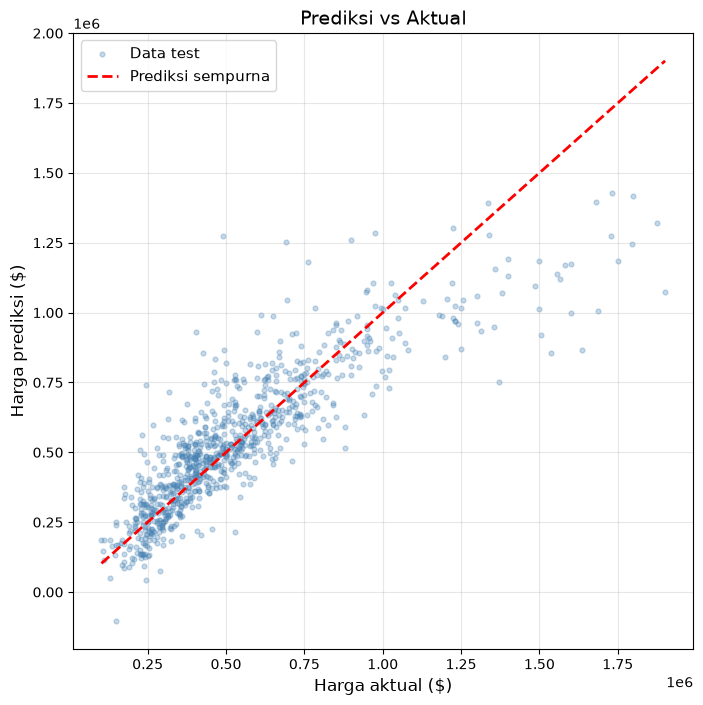

In [49]:
# ── Plot 1: Prediksi vs Aktual ──
fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(y_test, pred_test, s=12, alpha=0.3, color="steelblue", label="Data test")

# Garis ideal y = x
batas = [y_test.min(), y_test.max()]
ax.plot(batas, batas, color="red", linewidth=2, linestyle="--", label="Prediksi sempurna")

ax.set_title("Prediksi vs Aktual", fontsize=14)
ax.set_xlabel("Harga aktual ($)", fontsize=12)
ax.set_ylabel("Harga prediksi ($)", fontsize=12)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.show()

## 🎯 Ringkasan

| Konsep | Yang kita pelajari |
|---|---|
| **Model** | $\hat{y} = w_1x_1 + \dots + w_px_p + b$ |
| **One-hot encoding** | Mengubah fitur teks (lokasi) menjadi kolom angka 0/1 |
| **Pelatihan** | `LinearRegression().fit(X_train, y_train)` — meminimalkan MSE |
| **Split data** | 80% train / 20% test, agar evaluasi jujur |
| **Evaluasi** | RMSE — dan **selalu** bandingkan dengan baseline |
| **Cross-validation** | Menguji kestabilan model di beberapa pembagian data |

**Pelajaran terpenting:** fitur yang **tepat** jauh lebih berpengaruh daripada teknik yang canggih.
Menambahkan lokasi saja menurunkan RMSE dari \$219.647 ke \$148.696 — perbaikan 32% — hanya dengan
mengubah satu kolom teks menjadi 76 kolom angka.

**Yang masih bisa ditingkatkan:**
1. Lokasi masih kasar: `street` dan koordinat bisa menangkap lingkungan yang lebih spesifik.
2. `waterfront` dan `view` belum dipakai — padahal berkorelasi kuat dengan rumah mahal.
3. Hubungan harga dengan luas bangunan mungkin **tidak linear** — bisa dicoba model non-linear
   seperti decision tree, lalu dibandingkan apakah benar-benar lebih baik dari regresi linear.
4. Regularisasi (Ridge/Lasso) untuk menekan koefisien kode pos yang datanya sedikit.